# Postprocessing

In [17]:
%matplotlib widget
import matplotlib.pyplot as plt
import h5py
import numpy as np
import pandas as pd
from matplotlib.patches import Circle
import os
import myfunctions
import h5py
import TM26_unet as unet


GPU = True
MULTIGPU = True

DELETE_OLD_FILES = False
DELETE_OLD_FILES = False

SMALL_SIZE = 18
MEDIUM_SIZE = 22
BIGGER_SIZE = 24
GPU = True

diffLimDir = "dataInputs/"
testDataDir = "output_prep/"
outputDir = "output_post/"
inputDir = "output_infer/"

exposures = [10, 100]

# datasets_name = ["lightfield", "WFSxy", "WFSxy_DM", "WFSxy_DM_intensity", "WFSxy_intensity"]
datasets_name = ["WFSxy", "WFSxy_DM"]
# dataset_name_readable = ["lightfield", "WFSxy", "WFSxy and DM commands", "WFSxy, SHWFS intensity map and DM commands", "WFSxy and SHWFS intensity map"]
dataset_name_readable = ["WFSxy", "WFSxy and DM commands"]


D = 17.5e-3  # [m]
wl = 632.8e-9  # [m]
pad = 2
dx = 3.928571e-06

SMALL_SIZE = 18
MEDIUM_SIZE = 22
BIGGER_SIZE = 24
GPU = True

for i in range(len(datasets_name)):
    os.makedirs(outputDir + datasets_name[i]+"_long", exist_ok=True)

dataset_numbers = len(datasets_name)

### Inference data

In [18]:
for dataset_number in range(dataset_numbers):
    if datasets_name[dataset_number] == "lightfield":
        
        with h5py.File(inputDir+datasets_name[dataset_number]+"/predictions.h5", 'r') as temp:
            inferences = temp[list(temp.keys())[0]][()]
        with h5py.File("dataInputs/ipsf_difflim.h5", 'r') as temp:
            dx_scaling = temp[list(temp.keys())[0]][()].shape[1]/inferences.shape[1]
            ipsf_difflim = myfunctions.pixel_adder(temp[list(temp.keys())[0]][()],final_shape=[inferences.shape[1], inferences.shape[2]])   
            
        truths = np.zeros_like(inferences)
        with h5py.File(testDataDir+"ao_ipsf_test_1.h5", 'r') as temp:
            key = list(temp.keys())
            tempdata = temp[key[0]][()][:]
            for i in range(tempdata.shape[0]):
                truths[i,:,:] = myfunctions.pixel_adder(tempdata[i],final_shape=[inferences.shape[1], inferences.shape[2]])
        
    else:
        with h5py.File(inputDir+datasets_name[dataset_number]+"/predictions.h5", 'r') as temp:
            inferences = temp[list(temp.keys())[0]][()]
        with h5py.File("dataInputs/ipsf_difflim.h5", 'r') as temp:
            ipsf_difflim = temp[list(temp.keys())[0]][()]
            dx_scaling = temp[list(temp.keys())[0]][()].shape[1]/inferences.shape[1]
        with h5py.File(testDataDir+"ao_ipsf_test_1.h5", 'r') as temp:
            key = list(temp.keys())
            truths = temp[key[0]][()][:]

    x_max = np.genfromtxt("output_ML/"+datasets_name[dataset_number]+"/max_val.txt", delimiter=',', dtype=None, encoding='utf-8')[0][1]
    y_max = np.genfromtxt("output_ML/"+datasets_name[dataset_number]+"/max_val.txt", delimiter=',', dtype=None, encoding='utf-8')[1][1]
    dx_scaled = dx*dx_scaling
    


Computing OTF and Strehl ratios for exposure of 10 iterations (1/3)
output_post/WFSxy_DM/_long/WFSxy_DM_OTF10.png
Computing OTF and Strehl ratios for exposure of 100 iterations (2/3)


C:\Users\dominiqu.humbert\AppData\Local\Temp\ipykernel_9352\3029011148.py:70: ComplexWarning: Casting complex values to real discards the imaginary part
  otf[i] = myfunctions.otf_from_psf(padded_inferences)
C:\Users\dominiqu.humbert\AppData\Local\Temp\ipykernel_9352\3029011148.py:72: ComplexWarning: Casting complex values to real discards the imaginary part
  otf_real[i] = myfunctions.otf_from_psf(padded_truth)


output_post/WFSxy_DM/_long/WFSxy_DM_OTF100.png
Computing OTF and Strehl ratios for exposure of 1000 iterations (3/3)
output_post/WFSxy_DM/_long/WFSxy_DM_OTF1000.png
(3, 160, 160)
FWHM of the inferred PSF: 8 pixels
FWHM of the measured PSF: 6 pixels


C:\Users\dominiqu.humbert\AppData\Local\Temp\ipykernel_9352\3029011148.py:182: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax_dy.set_ylim([-ylim, ylim])
C:\Users\dominiqu.humbert\AppData\Local\Temp\ipykernel_9352\3029011148.py:193: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax_dx.set_xlim([-xlim, xlim])


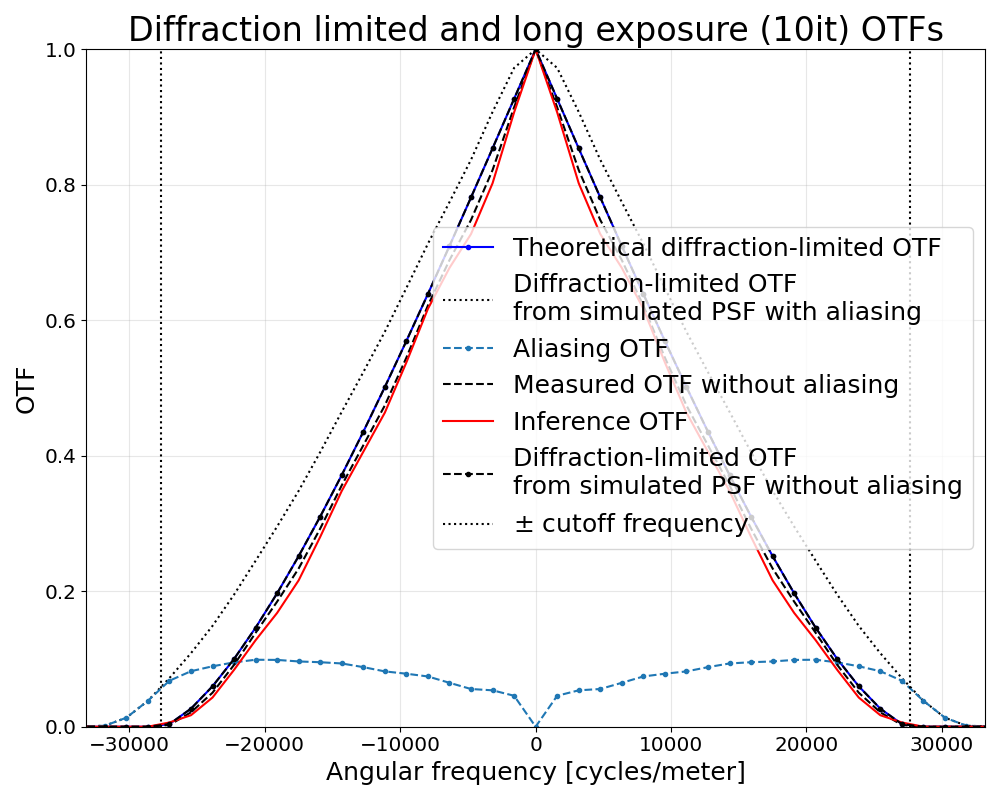

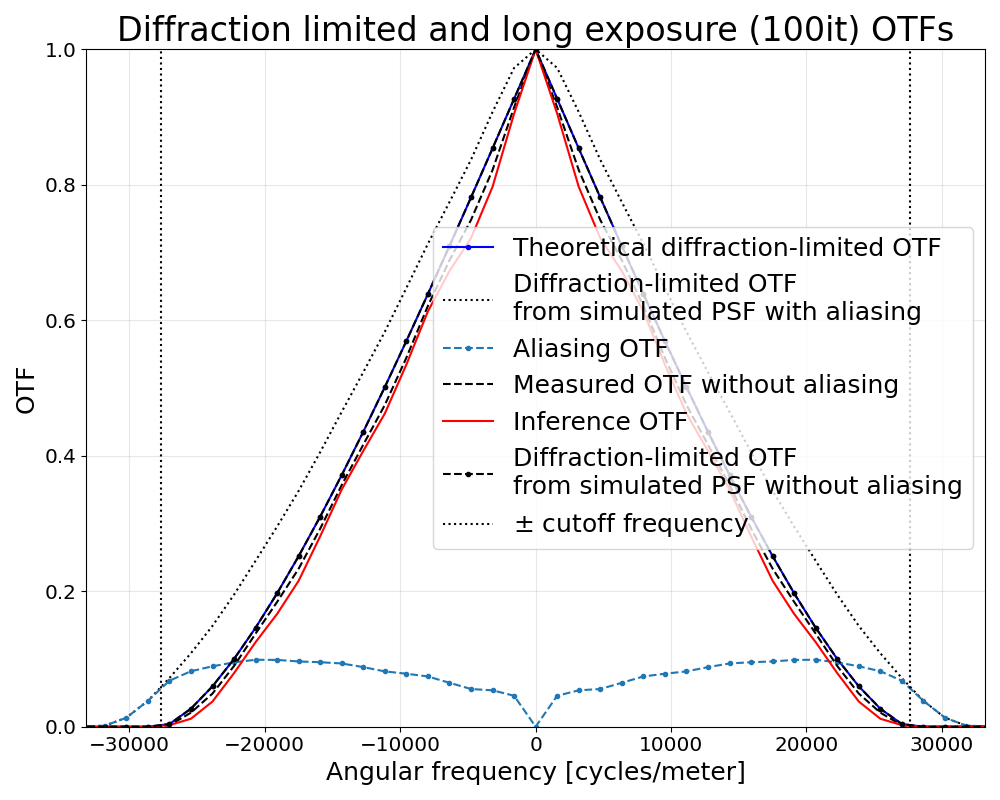

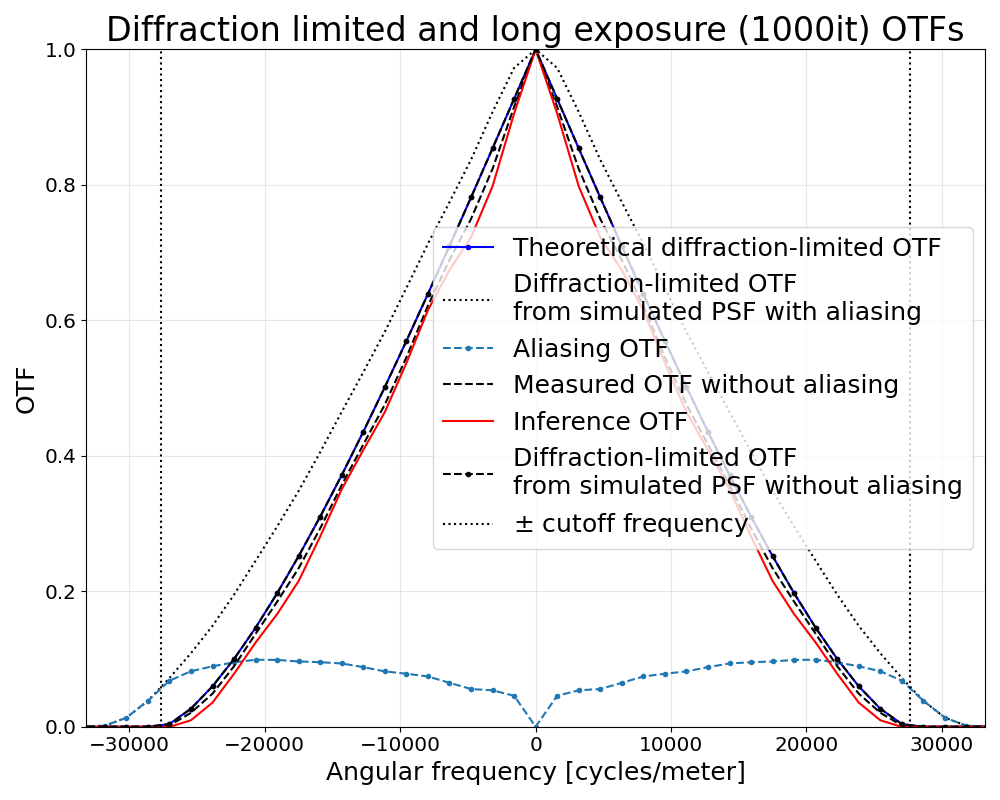

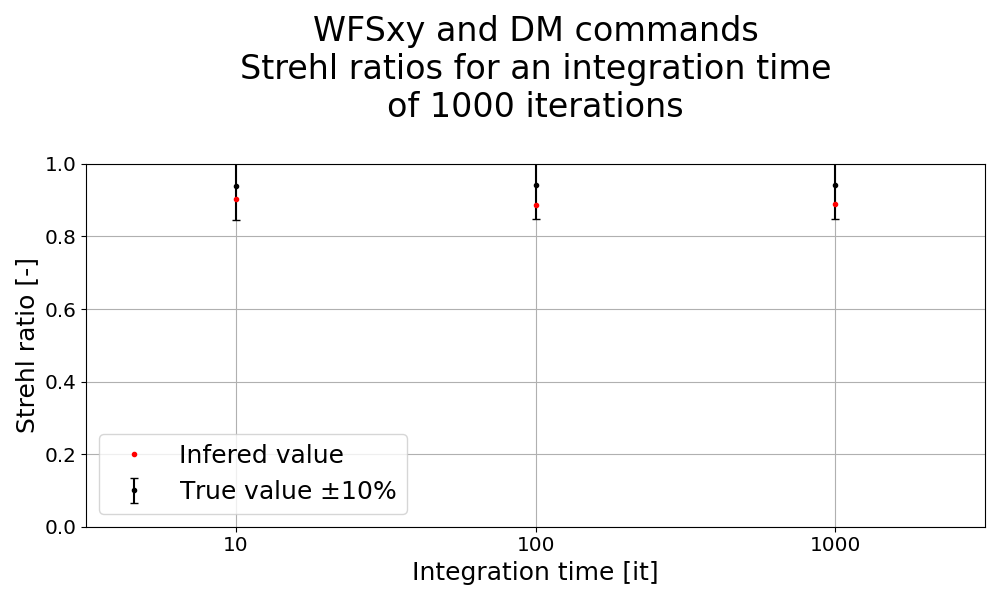

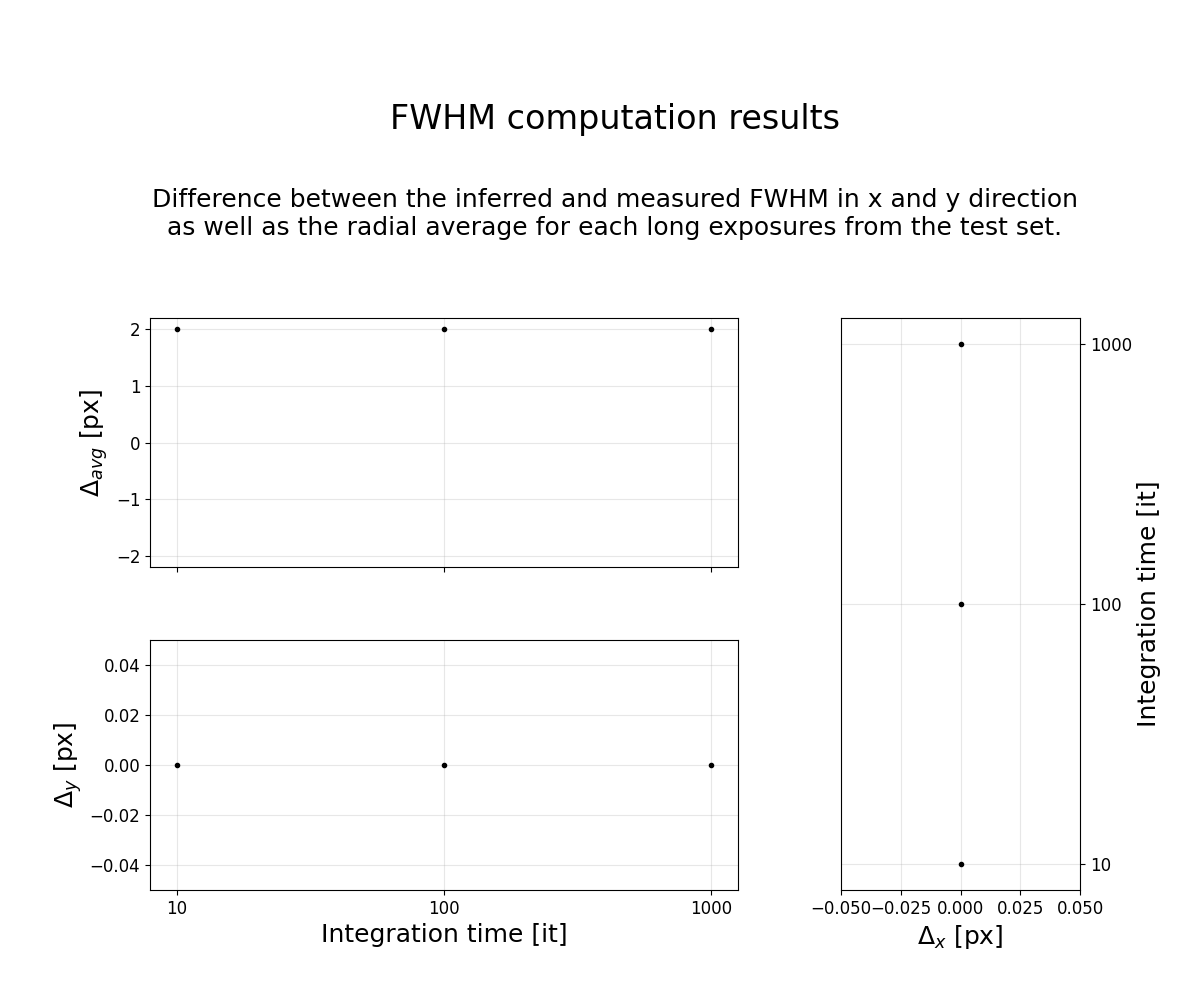

In [72]:
padded_ipsf_difflim = myfunctions.pad_center(ipsf_difflim, pad)/ipsf_difflim.max()
exposures = [10, 100, 1000]

OTF_truths = np.zeros((len(exposures),*padded_ipsf_difflim.shape))
OTF_inferences = np.zeros_like(OTF_truths)
inference_Strehls = np.zeros(len(exposures))
truths_Strehls = np.zeros(len(exposures))
Strehls_difference = np.zeros(len(exposures))
Strehls_rel_diff = np.zeros(len(exposures))

otf = np.zeros((len(exposures),*padded_ipsf_difflim.shape))
psfs_inferred_from_otf = np.zeros_like(otf)
otf_real = np.zeros_like(otf)
psfs_truth_from_otf = np.zeros_like(otf)

for i, exposure in enumerate(exposures):
    print(f"Computing OTF and Strehl ratios for exposure of {exposure} iterations ({i+1}/{len(exposures)})")

    psfsum_truth = truths[0:exposure,:,:]/y_max
    psfsum_truth = psfsum_truth.sum(axis=(0))/exposure

    psfsum_inference = inferences[0:exposure,:,:]
    psfsum_inference = psfsum_inference.sum(axis=(0))/exposure

    
    padded_truth = myfunctions.pad_center(psfsum_truth, pad)
    padded_inferences = myfunctions.pad_center(psfsum_inference,pad)

    N = ipsf_difflim.shape[1]*pad
    fc = D / wl
    freq = np.fft.fftshift(np.fft.fftfreq(N, d=dx_scaled))
    freq_n = np.abs(freq) / fc
    NU_X, NU_Y = np.meshgrid(freq_n, freq_n)
    nu_n_grid = np.sqrt(NU_X**2 + NU_Y**2)
    # FREQ_MASK = np.abs(freq) < fc
    FREQ_MASK = nu_n_grid < 1

    OTF_ipsf_difflim = np.abs(myfunctions.otf_from_psf(padded_ipsf_difflim))
    OTF_tel = myfunctions.telescope_otf(nu_n_grid)
    OTF_aliasing =OTF_ipsf_difflim - OTF_tel
    OTF_truths[i] = (np.abs(myfunctions.otf_from_psf(padded_truth)) - OTF_aliasing)*FREQ_MASK
    OTF_inferences[i] = (np.abs(myfunctions.otf_from_psf(padded_inferences)) - OTF_aliasing)*FREQ_MASK

    inference_Strehls[i] = np.sum(OTF_inferences[i]) / np.sum(OTF_tel*FREQ_MASK)
    truths_Strehls[i] = np.sum(OTF_truths[i]) / np.sum(OTF_tel*FREQ_MASK)
    Strehls_difference[i] = truths_Strehls[i] - inference_Strehls[i]
    Strehls_rel_diff[i] = Strehls_difference[i]/truths_Strehls[i]

    plt.figure(figsize=(10, 8))
    plt.plot(freq, OTF_tel[N//2, :], ".-b", label="Theoretical diffraction-limited OTF")
    plt.plot(freq, OTF_ipsf_difflim[N//2, :], "k", linestyle="dotted", label="Diffraction-limited OTF\nfrom simulated PSF with aliasing")
    plt.plot(freq, OTF_aliasing[N//2, :],"--.",label = "Aliasing OTF")
    plt.plot(freq, OTF_truths[i][N//2, :],"--k", label="Measured OTF without aliasing")
    plt.plot(freq, OTF_inferences[i][N//2, :]*FREQ_MASK[N//2,:],'r', label="Inference OTF")
    plt.plot(freq, OTF_ipsf_difflim[N//2, :]-OTF_aliasing[N//2, :], "--.k", label="Diffraction-limited OTF\nfrom simulated PSF without aliasing")
    plt.vlines([-fc, fc], 0, 1, "k", linestyles="dotted", label = r"$\pm$ cutoff frequency")
    plt.title(f"Diffraction limited and long exposure ({exposure}it) OTFs", fontsize = BIGGER_SIZE)
    plt.xlabel("Angular frequency [cycles/meter]", fontsize=SMALL_SIZE)
    plt.ylabel("OTF", fontsize=SMALL_SIZE)
    plt.xlim([-fc * 1.2, fc * 1.2])
    plt.ylim([0, 1])
    plt.xticks(fontsize=SMALL_SIZE*.8)
    plt.yticks(fontsize=SMALL_SIZE*.8)
    plt.grid(True, alpha=0.3)
    plt.legend(fontsize=SMALL_SIZE)
    plt.tight_layout()
    print(outputDir + datasets_name[dataset_number]+"/_long"+f"/{datasets_name[dataset_number]}_OTF{exposure}.png")
    plt.savefig(outputDir + datasets_name[dataset_number]+"_long"+f"/{datasets_name[dataset_number]}_OTF{exposure}.png")

    otf[i] = myfunctions.otf_from_psf(padded_inferences)
    psfs_inferred_from_otf[i] = myfunctions.otf_to_psf(otf[i],padded_inferences[...,:,:].sum())
    otf_real[i] = myfunctions.otf_from_psf(padded_truth)
    psfs_truth_from_otf[i] = myfunctions.otf_to_psf(otf_real[i],padded_truth[...,:,:].sum())

truths_Strehls = np.asarray(truths_Strehls)
inference_Strehls = np.asarray(inference_Strehls)

truth_errors = truths_Strehls * 0.10


x = np.arange(len(exposures))
truth_errors = truths_Strehls * 0.10

plt.figure(figsize=(10, 6))
plt.errorbar(x, truths_Strehls, yerr=truth_errors, fmt='.k', ecolor='k', capsize=3, label = r"True value $\pm$10%")
plt.plot(x, inference_Strehls, '.r',label = "Infered value")

plt.title(dataset_name_readable[dataset_number] + f"\nStrehl ratios for an integration time\nof {exposure} iterations\n", fontsize=BIGGER_SIZE)
plt.xticks(x, exposures,fontsize=SMALL_SIZE*.8)
plt.xlim([-0.5,len(exposures)-0.5])
plt.xlabel(f"Integration time [it]", fontsize=SMALL_SIZE)
plt.yticks(fontsize=SMALL_SIZE*.8)
plt.ylim([0, 1])
plt.ylabel("Strehl ratio [-]", fontsize=SMALL_SIZE)
plt.legend(fontsize=SMALL_SIZE)
plt.grid()
plt.tight_layout()

plt.savefig(outputDir + datasets_name[dataset_number]+"_long" f"/{datasets_name[dataset_number]}_Strehl.png")


inferred_FWHM_x = []
inferred_FWHM_y = []

print(psfs_inferred_from_otf.shape)

for i in range(psfs_inferred_from_otf.shape[0]):
    FWHM_x, FWHM_y = myfunctions.fwhm_2d(psfs_inferred_from_otf[i])
    inferred_FWHM_x.append(FWHM_x)
    inferred_FWHM_y.append(FWHM_y)

measured_FWHM_x = []
measured_FWHM_y = []
for i in range(psfs_truth_from_otf.shape[0]):
    FWHM_x, FWHM_y = myfunctions.fwhm_2d(psfs_truth_from_otf[i])
    measured_FWHM_x.append(FWHM_x)
    measured_FWHM_y.append(FWHM_y)

# radial average
inference_fwhm_r = []
for i in range(psfs_inferred_from_otf.shape[0]):
    rp = myfunctions.radial_average(psfs_inferred_from_otf[i])
    half_max = rp.max() / 2
    idx = np.where(rp >= half_max)[0]
    inference_fwhm_r.append((idx[-1] - idx[0])*2)
print(f"FWHM of the inferred PSF: {inference_fwhm_r[0]} pixels")
measured_fwhm_r = []
for i in range(psfs_truth_from_otf.shape[0]):
    rp = myfunctions.radial_average(psfs_truth_from_otf[i])
    half_max = rp.max() / 2
    idx = np.where(rp >= half_max)[0]
    measured_fwhm_r.append((idx[-1] - idx[0])*2)
print(f"FWHM of the measured PSF: {measured_fwhm_r[0]} pixels")

diff_FWHM_x = np.array(inferred_FWHM_x) - np.array(measured_FWHM_x)
diff_FWHM_y = np.array(inferred_FWHM_y) - np.array(measured_FWHM_y)
diff_FWHM_r = np.array(inference_fwhm_r) - np.array(measured_fwhm_r)

x = np.arange(len(exposures))

fig = plt.figure(figsize=(12, 10)) # https://matplotlib.org/3.5.0/tutorials/intermediate/gridspec.html
gs = GridSpec(
    3, 2,
    figure=fig,
    width_ratios=[3.2, 1.3],
    height_ratios=[.5, 1, 1],
    wspace=0.25,
    hspace=0.35
)

ax_text    = fig.add_subplot(gs[0, 0:])
ax_avg     = fig.add_subplot(gs[1, 0])
ax_dy      = fig.add_subplot(gs[2, 0], sharex=ax_avg)
ax_dx      = fig.add_subplot(gs[1:, 1])

# --- Top-left: title + explanation ---
ax_text.axis("off")
ax_text.text(0.5, 1, f"FWHM computation results", ha="center", va="center", fontsize=BIGGER_SIZE)
ax_text.text(0.5, 0.25, "Difference between the inferred and measured FWHM in x and y direction\nas well as the radial average for each long exposures from the test set.",
             ha="center", va="center", fontsize=18)
# --- Top-right: contour plot ---

# --- bottom plots ---
x = np.arange(len(exposures))
# delta_avg, delta_y, delta_x should be your arrays

ax_avg.plot(x, diff_FWHM_r, '.k')
ax_avg.set_ylabel(r'$\Delta_{avg}$ [px]', fontsize=18)
ax_avg.tick_params(axis='both', labelsize=12)
# ax_avg.set_yticks(x)
ax_avg.grid(True, alpha=0.3)
ylim = max(abs(np.min(diff_FWHM_r)), abs(np.max(diff_FWHM_r))) * 1.1
ax_avg.set_ylim([-ylim, ylim])

ax_dy.plot(x, diff_FWHM_y, '.k')
ax_dy.set_xticks(x,exposures)
ax_dy.set_xlabel(f"Integration time [it]", fontsize=18)
ax_dy.set_ylabel(r'$\Delta_y$ [px]', fontsize=18)
ax_dy.tick_params(axis='both', labelsize=12)
ax_dy.grid(True, alpha=0.3)
ylim = max(abs(np.min(diff_FWHM_y)), abs(np.max(diff_FWHM_y))) * 1.1
ax_dy.set_ylim([-ylim, ylim])

ax_dx.plot(diff_FWHM_x, x, '.k')
ax_dx.set_xlabel(r'$\Delta_x$ [px]', fontsize=18)
ax_dx.yaxis.set_label_position("right")
ax_dx.set_yticks(x,exposures)
ax_dx.yaxis.tick_right()
ax_dx.set_ylabel(f"Integration time [it]", fontsize=18)
ax_dx.tick_params(axis='both', labelsize=12)
ax_dx.grid(True, alpha=0.3)
xlim = max(abs(np.min(diff_FWHM_x)), abs(np.max(diff_FWHM_x))) * 1.1
ax_dx.set_xlim([-xlim, xlim])

ax_avg.tick_params(labelbottom=False)

plt.savefig(outputDir + datasets_name[dataset_number]+"_long" f"/{datasets_name[dataset_number]}_FWHM.png")



## Encircled energy

Within 1st Airy disk or radius $r_{Airy}= 1.22\frac{\lambda}{D}$ [rad]

[0.84108379 0.83789423 0.8393241 ]


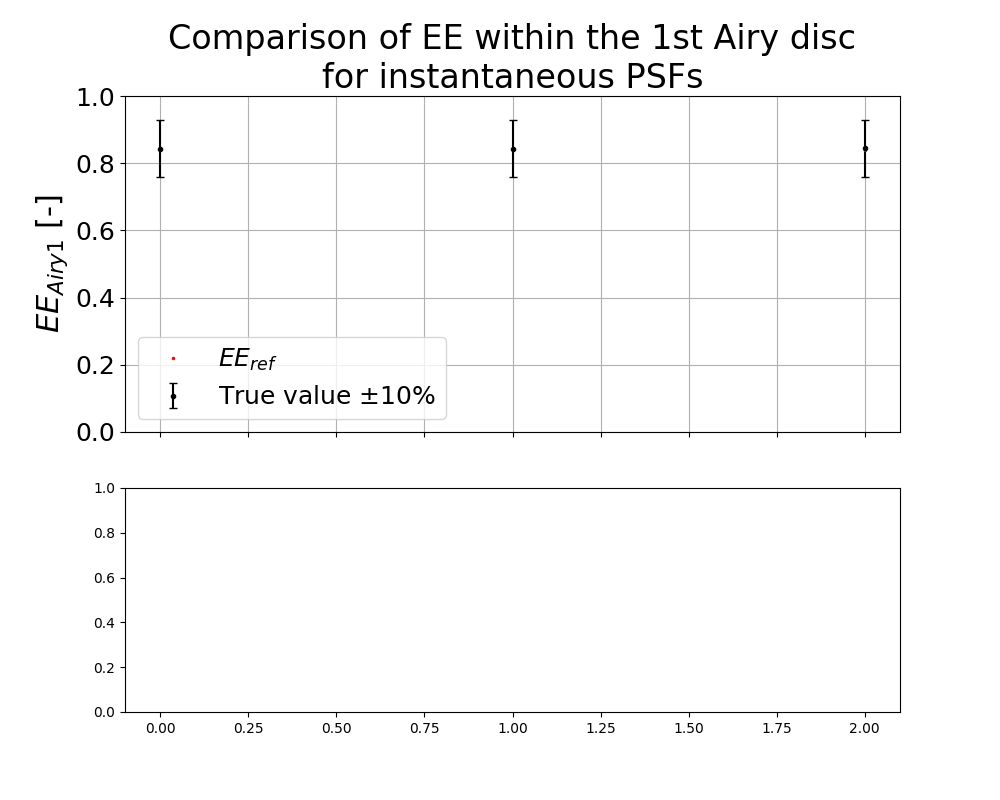

In [87]:
airy_r = 1.22*wl/D
airy_r_px = airy_r/dx_scaled
airy_d_px = 2*airy_r_px
AIRY_MASK = np.zeros_like(psfs_inferred_from_otf[0])

# Airy disk mask
y, x = np.indices(AIRY_MASK.shape)
rr = np.sqrt((x - AIRY_MASK.shape[1] // 2) ** 2 + (y - AIRY_MASK.shape[0] // 2) ** 2)
AIRY_MASK[rr < airy_r_px] = 1



norm_psfs_inferred_from_otf = psfs_inferred_from_otf / np.sum(psfs_inferred_from_otf,axis=(-2, -1), keepdims=True)
norm_psfs_truth_from_otf = psfs_truth_from_otf / np.sum(psfs_truth_from_otf,axis=(-2, -1), keepdims=True)

EE_inferred = np.sum(AIRY_MASK*norm_psfs_inferred_from_otf,axis=(-2, -1))
EE_measured = np.sum(AIRY_MASK*norm_psfs_truth_from_otf,axis=(-2, -1))
EE_diff = EE_measured - EE_inferred
EE_rel_diff = EE_diff/EE_measured

print(EE_inferred)
x = np.arange(len(exposures))

truth_errors = EE_measured * 0.10
plt.close('all')
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={'height_ratios': [3, 2]})

# Top plot: EE
ax.errorbar(x, EE_measured, yerr=truth_errors, fmt='.k', ecolor='k', capsize=3, label = r"True value $\pm$10%")
ax.plot(x, EE_inferred, '.r', label=r'$EE_{ref}$', markersize=3)
ax.set_ylim([0, 1])
ax.set_ylabel('$EE_{Airy1}$ [-]', fontsize=MEDIUM_SIZE)
ax.tick_params(axis='y', labelsize=SMALL_SIZE)
ax.legend(fontsize=SMALL_SIZE)
ax.set_title("Comparison of EE within the 1st Airy disc\nfor instantaneous PSFs", fontsize=BIGGER_SIZE)
# ax.set_xlim([0, EE_inferred.shape[0]])
ax.grid()

# Bottom plot: Relative distance (ax2 is now a separate subplot below)
# ax2.plot(EE_rel_diff * 100, '.-k', label=r"$\frac{S_{R}-S_{ref}}{S_{ref}}$",markersize=3)
# ax2.set_ylabel('Relative distance [%]', fontsize=MEDIUM_SIZE, color='k')
# ax2.tick_params(axis='y', labelsize=SMALL_SIZE, colors='k')
# symetric_lim = max(abs(np.min(EE_rel_diff) * 110), abs(np.max(EE_rel_diff) * 110))
# ax2.set_ylim([-symetric_lim, symetric_lim])
# ax2.legend(fontsize=MEDIUM_SIZE)
# # ax2.set_xlabel('Iteration [-]', fontsize=MEDIUM_SIZE)
# # ax2.set_xlim([0, EE_inferred.shape[0]])
# ax2.grid()
# # ax2.tick_params(axis='x', labelsize=SMALL_SIZE)
# plt.figtext(0.5, 0.01, f"At the computing scale, the\nAiry disk radius is {airy_r_px//1:.0f} px, floored from {airy_r_px:.0f} pixels.", ha="center", fontsize=MEDIUM_SIZE)
# plt.tight_layout(rect=[0, 0.08, 1, 1])
# plt.tight_layout()


# plt.savefig(outputDir + datasets_name[dataset_number]+"_long" f"/{datasets_name[dataset_number]}_Strehl.png")